# Brax: a differentiable physics engine

[Brax](https://github.com/google/brax) simulates physical systems made up of rigid bodies, joints, and actutators.  Brax provides the function:

$$
\text{state}_{t+1} = \text{step}(\text{system}, \text{state}_t, \text{act})
$$

where:
* $\text{system}$ is the static description of the physical system: each body in the world, its weight and size, and so on
* $\text{state}_t$ is the dynamic state of the system at time $t$: each body's position, rotation, velocity, and angular velocity
* $\text{act}$ is dynamic input to the system in the form of motor actuation

Brax simulations are differentiable: the gradient $\Delta \text{step}$ can be used for efficient trajectory optimization.  But Brax is also well-suited to derivative-free optimization methods such as evolutionary strategy or reinforcement learning.

Let's review how $\text{system}$, $\text{state}_t$, and $\text{act}$ are used:

In [1]:
import jax
import matplotlib.pyplot as plt
from brax.io import mjcf
from brax.positional import pipeline
from jax import numpy as jnp
from matplotlib.lines import Line2D
from matplotlib.patches import Circle

In [2]:
arr = jnp.array(6)
jnp.hstack([arr, arr])

Array([6, 6], dtype=int32, weak_type=True)

In [3]:
def visualize(ax, pos, alpha=1):
    for p, pn in zip(pos, list(pos[1:]) + [None], strict=False):
        ax.add_patch(
            Circle(
                xy=(p[0], p[2]), radius=0.5, fill=False, color=(0, 0, 0, alpha)
            )
        )
        if pn is not None:
            ax.add_line(
                Line2D([p[0], pn[0]], [p[2], pn[2]], color=(1, 0, 0, alpha))
            )

In [4]:
pendulum = mjcf.loads("""
<mujoco>
  <option timestep="0.01"/>
  <worldbody>
    <body pos="0 0 -0.5">
      <joint axis="0 1 0" type="hinge"/>
      <geom pos="0 0 -1.5" size=".1" type="sphere"/>
      <body pos="0 0 -1.5">
        <joint axis="0 1 0" type="hinge"/>
        <geom pos="0 0 -1.5" size=".1" type="sphere"/>
        <body pos="0 0 -1.5">
          <joint axis="0 1 0" type="hinge"/>
          <geom pos="0 0 -1.5" size=".1" type="sphere"/>
          <body pos="0 0 -1.5">
            <joint axis="0 1 0" type="hinge"/>
            <geom pos="0 0 -1.5" size=".1" type="sphere"/>
          </body>
        </body>
      </body>
    </body>
  </worldbody>
</mujoco>
""")
init_q = jnp.array([0, -0.75 * jnp.pi, 0.8 * jnp.pi, 0])
state = pipeline.init(pendulum, init_q, jnp.zeros(pendulum.qd_size()))

/Users/behrn/Projects/hcnn/.venv/lib/python3.13/site-packages/brax/io/mjcf.py:480: UserWarning: Brax System, piplines and environments are not actively being maintained. Please see MJX for a well maintained JAX-based physics engine: https://github.com/google-deepmind/mujoco/tree/main/mjx. For a host of environments that use MJX, see: https://github.com/google-deepmind/mujoco_playground.
  warnings.warn(


In [5]:
for q, qd in zip(state.q, state.qd, strict=False):
    print(f"{q}\t{qd}")

0.0	0.0
-2.356194496154785	0.0
2.5132741928100586	0.0
0.0	0.0


For maximal coordinates we denote position as $\text{x}$ and velocity $\text{xd}$.  In maximal coordinates, every link uses 3 values for location in 3D space, and 4 values for orientation (a quaternion).  Velocity uses 3 values for linear velocity and 3 more for angular velocity:

In [6]:
for pos, rot, vel, ang in zip(
    state.x.pos, state.x.rot, state.xd.vel, state.xd.ang, strict=False
):
    print(f"{pos}   \t{rot}\t{vel}\t{ang}")

[ 0.   0.  -0.5]   	[1. 0. 0. 0.]	[0. 0. 0.]	[0. 0. 0.]
[ 0.  0. -2.]   	[ 0.38268346  0.         -0.92387956  0.        ]	[0. 0. 0.]	[0. 0. 0.]
[ 1.0606602   0.         -0.93933976]   	[0.99691737 0.         0.07845911 0.        ]	[0. 0. 0.]	[0. 0. 0.]
[ 0.8260085  0.        -2.4208722]   	[0.99691737 0.         0.07845911 0.        ]	[0. 0. 0.]	[0. 0. 0.]


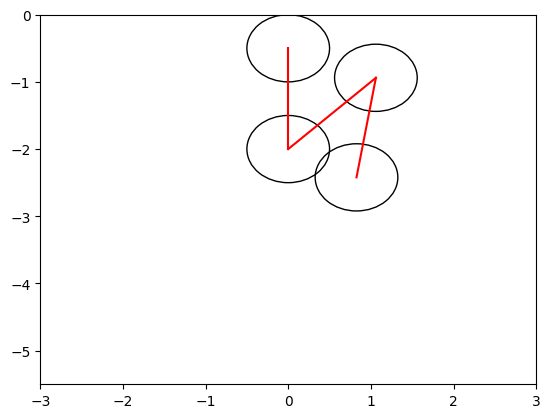

In [7]:
_, ax = plt.subplots()
plt.xlim([-3, 3])
plt.ylim([-5.5, 0])

visualize(ax, state.x.pos)
plt.show()

In [8]:
import itertools


@jax.jit
def test_collision(theta1, theta2, theta3):
    q = jnp.array([theta1, theta2, theta3, 0])
    state = pipeline.init(pendulum, q, jnp.zeros(pendulum.qd_size()))
    collision = False
    for i, j in itertools.combinations(state.x.pos, r=2):
        d = i - j
        collision = collision | (d.T @ d <= 1)
    return collision


n = 50
angles = jnp.linspace(-jnp.pi, jnp.pi, n)
T1, T2, T3 = jnp.meshgrid(angles, angles, angles, indexing="xy")
T1R = T1.ravel()
T2R = T2.ravel()
T3R = T3.ravel()

collision = jax.vmap(test_collision, in_axes=(0, 0, 0))(T1R, T2R, T3R).reshape(
    (n, n, n)
)

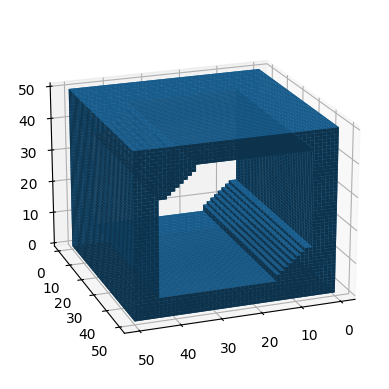

In [9]:
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.view_init(elev=20, azim=70, roll=0)
ax.voxels(collision)
plt.show()